# Cell phenotyping against a human reference

A segmenter gives us cells. Phenotyping gives each cell an identity — epithelial, T cell, CD4⁺ T cell — and the whole
downstream analysis (neighborhoods, niches) is built on those identities. This notebook asks how well our identities agree
with a biologist's, and which part of the pipeline the errors come from. It runs on the first human phenotype reference delivered:
the tagged window W1 (`SLIDE-0235/phenotyping/original_delivery/window_R1/`, notebook 00c), a 1024² window in region 1 of SLIDE-0235 in which a biologist labeled,
in four separate sessions, every epithelial cell, every T cell, every CD4⁺ T cell and every CD8⁺ T cell. The window lies on
the development slide, now fully expert-reviewed (all 16 regions carry QC tables; region 1 holds 320 flagged nuclei, which never
enter the HALO reference below), so it is where the phenotyping rule may be designed. The paper's rule (`configs/panel.yaml`) is set by
`scripts/calibrate_gates.py` on the whole unified store (`<slide>/phenotyping/`, notebook 00d: the R11/R12 boxes and this window) and then
frozen and applied to the test slides; the gates calibrated here on the window alone are a diagnostic of what one window can set, not the
paper's rule.

**The words used below**

| term | meaning here |
|---|---|
| **tag** | the biologist's label on one cell in one session: *positive* (tagged as that phenotype) or *negative* (left untagged — the sessions were exhaustive) |
| **marker mean** | the mean intensity of one marker inside a cell's mask, from the stored nine-marker stack (the files' own intensity columns are ignored) |
| **gate** | a threshold on one marker mean: above it the cell is *positive* for that marker. The panel (`configs/panel.yaml`) turns marker positivity into phenotypes by a fixed hierarchy: PanCK⁺ → Epithelial, CD3⁺ → T cell, CD3⁺CD4⁺ → CD4⁺ T cell, and so on |
| **mixture gate** | an *automatic* threshold: two Gaussians fitted to the log marker means, the gate where the brighter one takes over. Needs no reference — and is examined here to show what an automatic rule costs |
| **calibrated gate** | the threshold that best reproduces the biologist's tags. It *uses* the reference, so it is scored by cross-validation (set on four fifths of the cells, scored on the remaining fifth). The same recipe, run over the unified store by `scripts/calibrate_gates.py`, sets the paper's gates in `configs/panel.yaml` (slide-normalized units); here it is run on the window alone and the result goes to `outputs/analysis/gates_calibrated.yaml` for comparison |
| **normalized units** | a marker mean expressed as a fraction of the slide's stored intensity window (`stats.json`, 1st to 99.7th percentile) — the same scale the networks see, so a gate set on one slide transfers to another |
| **AUROC** | how well a score ranks positives above negatives, without any threshold: 0.5 is a coin flip, 1.0 is perfect separation. It says whether the information is there at all, before a gate is chosen |
| **probe** | a linear classifier trained to predict the tag from a set of features, scored by cross-validation; its AUROC measures how much identity information the features carry |
| **markers** (as features) | the seven marker means of the cell (PanCK, uPAR, CD3, CD4, CD8, FOXP3, CD45) |
| **tokens** | the feature vector a *frozen* image encoder produces for the cell's location — KODIAK's self-supervised ViT-B/16 encoder before any fine-tuning (`runs/kodiak_mxif_vitb`), or the DINOv3 ViT-B/16 weights it started from — computed from the segmenter input (LAP2 red, DAPI blue, nothing else). No phenotype marker is visible to it: it can only know identity from nuclear shape, texture and context |
| **tokens + markers** | both feature sets concatenated, to ask whether the image adds anything to the intensities |
| **kept / mistyped / lost** | for a tagged cell under a segmenter: found and given the right identity / found but given another identity / no predicted cell overlaps it enough to carry the tag over |

| section | question |
|---|---|
| 1 | the reference: how many cells, how many tags |
| 2 | does the marker carry the identity at all? (threshold-free) |
| 3 | turning intensity into a call: the gate, calibrated on the tags, against an automatic one |
| 4 | beyond intensity: what the image itself says about identity (tokens) |
| 5 | what each segmenter does to the tagged cells |
| 6 | the test slide: how much the phenotype composition depends on the gate |

In [1]:
import os, re, time
from pathlib import Path
import cv2, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy import ndimage as ndi
from scipy.stats import spearmanr
from shapely import wkt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from mxdata import DEFAULT_DATASET, ingest, load_config, load_regions
from mxdata.data.composite import render_channels, scaled
from mxdata.io import Box
from mxdata.pipeline.stats import NormStats
from mxseg.analysis import assign_phenotypes, load_panel
from mxseg.baselines import from_config
from mxseg.inputs import dataset_norms
from mxseg.metrics import iou_matrix, relabel
from mxseg.tiling import predict_tiled
from kodiak import Kodiak
from kodiak.components import DinoV3Encoder

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
torch.set_grad_enabled(False)
torch.set_num_threads(max(2, (os.cpu_count() or 8) // 2))                      # CPU only: the GPU belongs to the training job
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET = Path(os.environ.get("MXDATA_DATASET", DEFAULT_DATASET))
from mxdata.phenotyping import phenotyping_dir
ANNOT = Path(os.environ.get("MXDATA_ANNOTATED", phenotyping_dir("SLIDE-0235", DATASET.parent) / "original_delivery" / "window_R1"))   # the tool window, unified store
ANALYSIS = REPO / "outputs" / "analysis"

# ---- edit here ---------------------------------------------------------------------------------------------------------
SLIDE = "SLIDE-0235"
STEM = "SLIDE-0235_Final_x8192_y3072_l0"
SIZE = 1024
SESSIONS = {"Epithelial": ("_PanCK.csv", {"PanCK"}), "T cell": (".Tcell.csv", {"Tcell", "Tcqell"}),
            "CD4+ T cell": (".CD4+Tcell.csv", {"CD4+Tcell"}), "CD8+ T cell": (".CD8+Tcell.csv", {"CD8+Tcell"})}
SEED = 0                                  # the fine-tuning seed run on the window
ROWS = ["unet_flows", "kodiakb_flows", "dinov3b_flows", "kodiakb_frozen", "dinov3b_frozen", "cellpose_ft"]   # segmenters (ViT-B only, 10-epoch budget), paper order
PRETRAIN = REPO / "runs" / "kodiak_mxif_vitb" / "checkpoints" / "last.ckpt"     # KODIAK ViT-B/16 of record, before any fine-tuning (its EMA teacher)
DINO_W = REPO / "weights" / "dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth"    # the DINOv3 ViT-B/16 the KODIAK run started from
CROPS = {"Epithelial": (300, 200), "T cell": (512, 512)}   # (y, x) of the 512² crops drawn in section 3, one per phenotype
# ------------------------------------------------------------------------------------------------------------------------

INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
CHIP = dict(boxstyle="round,pad=0.22", fc="black", ec="none", alpha=0.6)
LABEL = {"unet_flows": "U-Net", "kodiakb_flows": "KODIAK B/16", "dinov3b_flows": "DINOv3 B/16", "kodiakb_frozen": "KODIAK B/16, frozen",
         "dinov3b_frozen": "DINOv3 B/16, frozen", "cellpose_ft": "Cellpose, adapted", "tool": "annotation tool", "halo": "HALO"}
MCOLOR = {"unet_flows": "#2A78D6", "kodiakb_flows": "#7E1F2E", "dinov3b_flows": "#6E5314", "kodiakb_frozen": "#DF959E",
          "dinov3b_frozen": "#D3BF8C", "cellpose_ft": "#EB6834", "tool": "#5C5F63", "halo": "#8A8A8A"}
GATE_COLOR = {"mixture gate (automatic)": "#9AA3AD", "calibrated gate (from the tags, CV)": "#1BAF7A", "multi-marker classifier (CV)": "#9A86E0"}
ENC_COLOR = {"markers (7 means)": "#2A78D6", "DINOv3 tokens (image only)": "#6E5314", "KODIAK tokens (image only)": "#7E1F2E", "KODIAK tokens + markers": "#DF959E"}
OUT_COLOR = {"correct": "#1BAF7A", "mistyped": "#EDA100", "lost": "#8E5BE0"}

def panel(ax, letter, dx=-0.04, dy=1.04):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)

def chip(ax, text):
    ax.text(0.02, 0.975, text, transform=ax.transAxes, fontsize=7.0, fontweight="bold", color="white", va="top", bbox=CHIP)

def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def xgrid(ax):
    ax.grid(axis="x", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def hexrgb(h):
    return np.array([int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)])

cfg = load_config(REPO / "configs" / "dataset.yaml")
PANEL = load_panel(REPO / "configs" / "panel.yaml")
MARKERS = list(cfg.markers)
GATE_M = PANEL.gate_markers                                                       # the seven phenotype markers
GATE = {p.name: p.marker for p in PANEL.phenotypes}
stats = NormStats.load(DATASET / SLIDE / "stats.json")
paths, mx, _ = ingest(SLIDE, None)
PX = float(mx.pixel_size_um or 0.325)
m_ = re.search(r"_x(\d+)_y(\d+)_l(\d+)$", STEM); X0, Y0 = int(m_.group(1)), int(m_.group(2))
W = Box(X0, Y0, X0 + SIZE, Y0 + SIZE)
STACK = mx.read_region(W, MARKERS, 0)                                             # (9, 1024, 1024) uint16
IMG = {mk: STACK[i].astype(np.float32) for i, mk in enumerate(MARKERS)}
regions = {r.region_id: r for r in load_regions(paths, None, cfg.min_area_px)}
R1 = regions[1]
halo_lab = R1.label_map(W).astype(np.int32)
wrong = set(R1.nuclei[R1.nuclei.flag == "WRONG"].nucleus_id) if "nucleus_id" in R1.nuclei else set()
halo_lab[np.isin(halo_lab, list(wrong))] = 0                                      # flagged HALO cells never enter

def load_session(suffix, tags):
    d = pd.read_csv(ANNOT / f"{STEM}{suffix}")
    d["positive"] = d.cell_type.isin(tags) & (d.tag == "accepted")
    rings = [np.asarray(wkt.loads(p).exterior.coords, float)[:, :2] - [X0, Y0] for p in d.polygon]
    lab = np.zeros((SIZE, SIZE), np.int32)
    for cid, ring in zip(d.cell_id, rings):
        cv2.fillPoly(lab, [np.round(ring).astype(np.int32)], int(cid))
    return d[["cell_id", "x", "y", "area_px", "positive"]].copy(), lab

def measure(lab, ids):
    """Mean of every gate marker inside each mask, raw counts (what notebook 03 measures)."""
    out = {"id": np.asarray(ids)}
    for mk in GATE_M:
        out[mk] = np.asarray(ndi.mean(IMG[mk], labels=lab, index=ids), float)
    return pd.DataFrame(out)

S = {}
for name, (suf, tags) in SESSIONS.items():
    d, lab = load_session(suf, tags)
    S[name] = dict(df=d.merge(measure(lab, d.cell_id.to_numpy()), left_on="cell_id", right_on="id"), lab=lab)
    print(f"{name:<12} {suf:<15} {len(d):>5} cells, {int(d.positive.sum()):>5} tagged | gate marker {GATE[name]}")

# ---- gates and probes ----------------------------------------------------------------------------------------------------
def gmm_threshold(values):
    """Two Gaussians on log intensity; the gate is where the brighter component takes over (posterior 0.5) above the dim mean."""
    v = np.log1p(np.asarray(values, float)).reshape(-1, 1)
    g = GaussianMixture(2, n_init=3, random_state=0).fit(v)
    hi = int(np.argmax(g.means_.ravel())); lo_mean = float(g.means_.ravel()[1 - hi])
    grid = np.linspace(v.min(), v.max(), 3000)
    post = g.predict_proba(grid.reshape(-1, 1))[:, hi]
    ok = (grid > lo_mean) & (post >= 0.5)
    return float(np.expm1(grid[ok][0])) if ok.any() else float(np.expm1(np.median(v)))

def calibrated_calls(values, y, k=5):
    """The gate a biologist's tags would set: per fold, the F1-maximizing threshold on the other folds; out-of-fold calls."""
    v, y = np.asarray(values, float), np.asarray(y, bool); call = np.zeros(len(v), bool)
    for tr, te in StratifiedKFold(k, shuffle=True, random_state=0).split(v, y):
        best_t, best_f = np.inf, -1.0
        for t in np.quantile(v[tr], np.linspace(0.3, 0.999, 300)):
            c = v[tr] > t; tp = (c & y[tr]).sum(); f = 2 * tp / max(2 * tp + (c & ~y[tr]).sum() + (~c & y[tr]).sum(), 1)
            if f > best_f:
                best_f, best_t = f, t
        call[te] = v[te] > best_t
    return call

def best_threshold(values, y):
    """The F1-maximizing threshold on all the given cells (used to draw a gate and to apply one; scoring uses the CV version)."""
    v, y = np.asarray(values, float), np.asarray(y, bool); best_t, best_f = np.inf, -1.0
    for t in np.quantile(v, np.linspace(0.3, 0.999, 400)):
        c = v > t; tp = (c & y).sum(); f = 2 * tp / max(2 * tp + (c & ~y).sum() + (~c & y).sum(), 1)
        if f > best_f:
            best_f, best_t = f, t
    return float(best_t)

def cv_scores(X, y, k=5, pca=None):
    """Out-of-fold decision scores of a balanced logistic regression on standardized (optionally PCA-reduced) features."""
    X, y = np.asarray(X, float), np.asarray(y, bool); s = np.zeros(len(y))
    for tr, te in StratifiedKFold(k, shuffle=True, random_state=0).split(X, y):
        steps = [StandardScaler()] + ([PCA(min(pca, len(tr) - 1), random_state=0)] if pca else []) + [LogisticRegression(max_iter=5000, class_weight="balanced", C=0.3)]
        s[te] = make_pipeline(*steps).fit(X[tr], y[tr]).decision_function(X[te])
    return s

def auroc(score, y):
    s, y = np.asarray(score, float), np.asarray(y, bool)
    r = pd.Series(s).rank().to_numpy()
    return float((r[y].sum() - y.sum() * (y.sum() + 1) / 2) / (y.sum() * (~y).sum()))

def average_precision(score, y):
    s, y = np.asarray(score, float), np.asarray(y, bool); o = np.argsort(-s); y = y[o]
    tp = np.cumsum(y); prec = tp / np.arange(1, len(y) + 1)
    return float((prec * y).sum() / max(y.sum(), 1))

def prf(call, y):
    call, y = np.asarray(call, bool), np.asarray(y, bool)
    tp, fp, fn = int((call & y).sum()), int((call & ~y).sum()), int((~call & y).sum())
    return {"precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1), "tp": tp, "fp": fp, "fn": fn}

def in_chain(pheno, target):
    """The assigned phenotype is ``target`` or a descendant (a Treg is a CD4+ T cell is a T cell; uPAR+ epithelial is Epithelial)."""
    return pheno.map(lambda n: n != "Other" and target in [p.name for p in PANEL.chain(n)])

def assign(tab, thresholds):
    return assign_phenotypes(tab[GATE_M], PANEL, thresholds)[0]

Epithelial   _PanCK.csv       1283 cells,  1006 tagged | gate marker PanCK
T cell       .Tcell.csv       1277 cells,    40 tagged | gate marker CD3


CD4+ T cell  .CD4+Tcell.csv   1277 cells,    26 tagged | gate marker CD4
CD8+ T cell  .CD8+Tcell.csv   1291 cells,    12 tagged | gate marker CD8


## 1. The reference

In [2]:
ref = pd.DataFrame([{"phenotype": n, "gate marker": GATE[n], "cells in the session": len(s_["df"]), "tagged (positive)": int(s_["df"].positive.sum()),
                     "untagged (negative)": int((~s_["df"].positive).sum())} for n, s_ in S.items()])
display(ref.style.hide(axis="index"))
print("each session is one exhaustive labeling of the annotation tool's own cells in the window; a cell is positive for the session's phenotype or negative")

phenotype,gate marker,cells in the session,tagged (positive),untagged (negative)
Epithelial,PanCK,1283,1006,277
T cell,CD3,1277,40,1237
CD4+ T cell,CD4,1277,26,1251
CD8+ T cell,CD8,1291,12,1279


each session is one exhaustive labeling of the annotation tool's own cells in the window; a cell is positive for the session's phenotype or negative


## 2. Does the marker carry the identity?

Before any threshold: take each cell's mean of the phenotype's gate marker (PanCK for Epithelial, CD3 for T cell, …) and
ask how well that single number ranks the tagged cells above the untagged ones. That is the AUROC. If it is near 1 the
marker knows the identity and any failure later is the gate's fault; if it is low, no gate on that marker can work.

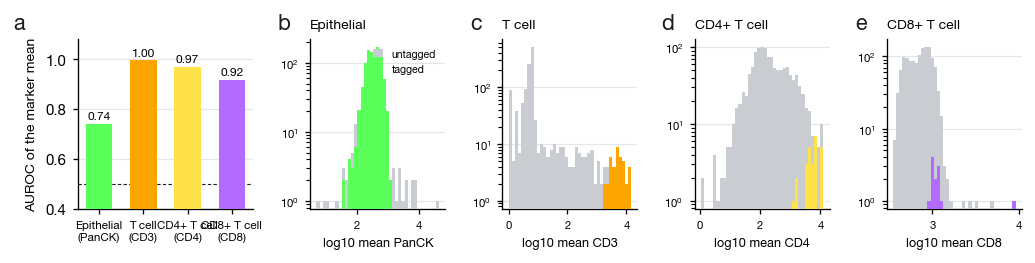

In [3]:
for name, s_ in S.items():
    d, mk = s_["df"], GATE[name]
    s_["auroc"] = auroc(d[mk], d.positive.to_numpy())
x = np.arange(len(SESSIONS)); w = 0.2
fig, axes = plt.subplots(1, 5, figsize=(7.6, 2.2), gridspec_kw=dict(width_ratios=[1.3, 1, 1, 1, 1], wspace=0.4), constrained_layout=False)
fig.subplots_adjust(left=0.07, right=0.99, top=0.85, bottom=0.28)
a = axes[0]
a.bar(x, [S[n]["auroc"] for n in SESSIONS], 0.6, color=[PANEL.colors[GATE[n]] for n in SESSIONS], zorder=3)
for xi, n in zip(x, SESSIONS):
    a.text(xi, S[n]["auroc"] + 0.01, f"{S[n]['auroc']:.2f}", ha="center", fontsize=6.4, va="bottom")
a.axhline(0.5, color=INK, lw=0.6, ls=(0, (3, 2)))
a.set_xticks(x, [f"{n}\n({GATE[n]})" for n in SESSIONS], fontsize=6.2); a.set_ylabel("AUROC of the marker mean", fontsize=7.4); a.set_ylim(0.4, 1.08); ygrid(a)
panel(a, "a", dx=-0.3)
for k, name in enumerate(SESSIONS):
    ax = axes[k + 1]; d, mk = S[name]["df"], GATE[name]
    v = np.log10(d[mk] + 1); bins = np.linspace(v.min(), v.max(), 40)
    ax.hist(v[~d.positive], bins=bins, color="#C9CDD2", zorder=3, label="untagged")
    ax.hist(v[d.positive], bins=bins, color=PANEL.colors[mk], zorder=4, label="tagged")
    ax.set_yscale("log"); ax.set_title(f"{name}", fontsize=7.4); ax.set_xlabel(f"log10 mean {mk}", fontsize=6.8); ax.tick_params(labelsize=6)
    if k == 0:
        ax.legend(fontsize=5.6, loc="upper right", handlelength=1.0)
    ygrid(ax); panel(ax, "bcde"[k], dx=-0.15)
plt.show()
print("AUROC of the gate marker alone: " + ", ".join(f"{n} ({GATE[n]}) {S[n]['auroc']:.3f}" for n in SESSIONS))


**Figure 1 — Is the identity in the marker?** (a) AUROC of the gate marker's mean per phenotype. (b–e) The log marker
means of every cell in the session, tagged cells in the marker's color over the untagged rest (log counts). CD3 ranks the
40 T cells above every other cell (AUROC 1.00): the tagged cells are the entire bright tail. CD4 and CD8 nearly do the
same. PanCK does not: the tagged epithelium and the untagged rest overlap almost completely, because the crypt epithelium of
this region barely stains for PanCK — the biologist typed these cells from their morphology, and no gate on this marker can
follow. So for three phenotypes the question is only *where to put the threshold*; for the epithelium the marker is the
wrong instrument.

## 3. Turning intensity into a call: the gate

A phenotype call needs a threshold on the marker mean. The paper's rule is the **calibrated gate**: the threshold that
best reproduces the biologist's tags, scored here by cross-validation so it is never scored on the cells it was set on.
To show what a reference is worth, it is compared with an **automatic** rule that needs none, the mixture gate, and with
a cross-validated **multi-marker classifier** on all seven marker means, the ceiling of what intensity alone can do. All
three go through the same panel hierarchy: a cell counts as, say, a T cell if its assigned phenotype is T cell or a
descendant (CD4⁺ T cell, CD8⁺ T cell, Treg). At the end the window's calibrated gates are written out in normalized units
(`outputs/analysis/gates_calibrated.yaml`), to compare with the paper's gates in `configs/panel.yaml`.

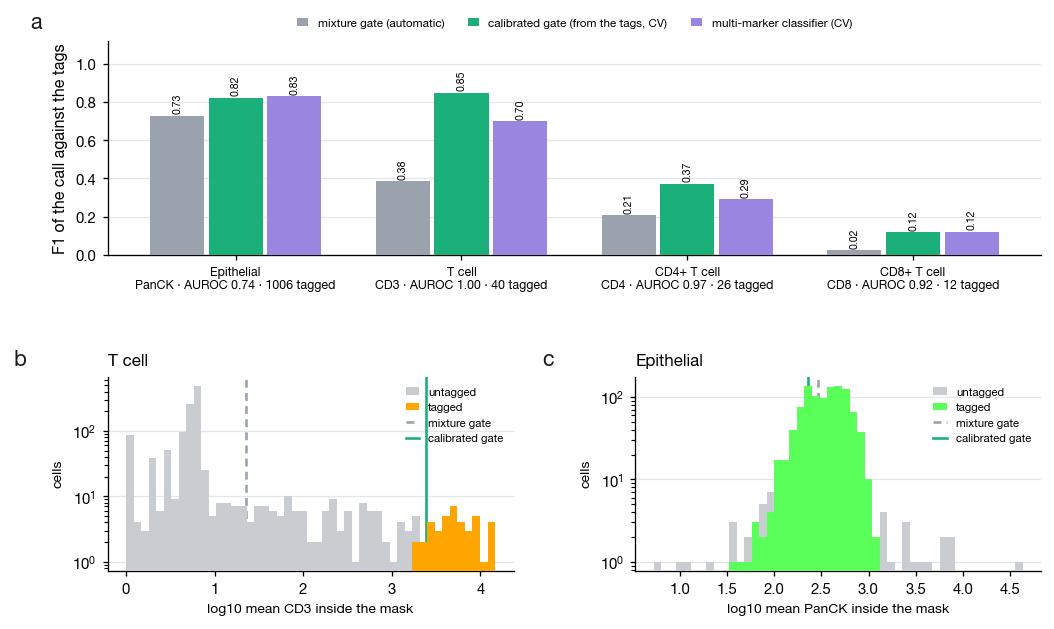

gate         calibrated gate (from the tags, CV)  mixture gate (automatic)  multi-marker classifier (CV)
phenotype                                                                                               
CD4+ T cell                                0.373                     0.206                         0.291
CD8+ T cell                                0.120                     0.024                         0.120
Epithelial                                 0.825                     0.731                         0.830
T cell                                     0.851                     0.385                         0.702
calibrated gates, normalized units: PanCK 0.018 (raw 225), CD3 0.195 (raw 2409), CD4 0.396 (raw 4713), CD8 0.152 (raw 1167) | provisional (no tags, mixture): uPAR 0.189, FOXP3 0.133, CD45 0.046 -> /Users/marjan/Desktop/MedAI/NeurIPSWorkshop/outputs/analysis/gates_calibrated.yaml


In [4]:
rows = []
for name, s_ in S.items():
    d, mk = s_["df"], GATE[name]
    y = d.positive.to_numpy()
    logm = np.log1p(d[GATE_M].to_numpy())
    thr_gmm = {m2: gmm_threshold(d[m2]) for m2 in GATE_M}
    calls = {"mixture gate (automatic)": in_chain(assign(d, thr_gmm), name).to_numpy(),
             "calibrated gate (from the tags, CV)": calibrated_calls(d[mk], y),
             "multi-marker classifier (CV)": cv_scores(logm, y) > 0}
    for gate, call in calls.items():
        rows.append({"phenotype": name, "gate": gate, **prf(call, y), "n_tagged": int(y.sum()), "n_called": int(call.sum())})
    s_["thr_gmm"] = thr_gmm
gates = pd.DataFrame(rows)

fig = plt.figure(figsize=(7.6, 4.9))
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1], hspace=0.6, wspace=0.3, left=0.08, right=0.99, top=0.9, bottom=0.1)
a = fig.add_subplot(gs[0, :])
w = 0.26
for j, gate in enumerate(GATE_COLOR):
    v = [gates[(gates.phenotype == n) & (gates.gate == gate)].F1.iloc[0] for n in SESSIONS]
    a.bar(x + (j - 1) * w, v, w * 0.92, color=GATE_COLOR[gate], zorder=3, label=gate)
    for xi, vi in zip(x + (j - 1) * w, v):
        a.text(xi, vi + 0.01, f"{vi:.2f}", ha="center", fontsize=5.6, rotation=90, va="bottom")
a.set_xticks(x, [f"{n}\n{GATE[n]} · AUROC {S[n]['auroc']:.2f} · {int(S[n]['df'].positive.sum())} tagged" for n in SESSIONS], fontsize=6.6)
a.set_ylabel("F1 of the call against the tags"); a.set_ylim(0, 1.12); ygrid(a); a.legend(fontsize=6.2, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.16), handlelength=1.0)
panel(a, "a", dx=-0.07)
for k, name in enumerate(("T cell", "Epithelial")):
    ax = fig.add_subplot(gs[1, k]); d, mk = S[name]["df"], GATE[name]
    v = np.log10(d[mk] + 1); bins = np.linspace(v.min(), v.max(), 50)
    ax.hist(v[~d.positive], bins=bins, color="#C9CDD2", label="untagged", zorder=3)
    ax.hist(v[d.positive], bins=bins, color=PANEL.colors[mk], label="tagged", zorder=4)
    ax.axvline(np.log10(S[name]["thr_gmm"][mk] + 1), color=GATE_COLOR["mixture gate (automatic)"], lw=1.4, ls=(0, (3, 2)), label="mixture gate")
    cal = best_threshold(d[mk], d.positive.to_numpy())
    ax.axvline(np.log10(cal + 1), color=GATE_COLOR["calibrated gate (from the tags, CV)"], lw=1.4, label="calibrated gate")
    ax.set_yscale("log"); ax.set_xlabel(f"log10 mean {mk} inside the mask", fontsize=7.4); ax.set_ylabel("cells", fontsize=7.4); ax.set_title(name)
    ax.legend(fontsize=6, loc="upper right", handlelength=1.2); ygrid(ax); panel(ax, "bc"[k], dx=-0.2)
plt.show()
print(gates.pivot(index="phenotype", columns="gate", values="F1").round(3).to_string())

# the paper's gates: calibrated on all tagged cells, in slide-normalized units; the untagged markers get a provisional mixture gate
import yaml
LOHI = {mk: (float(stats.lo[mk]), float(stats.hi[mk])) for mk in GATE_M}
to_norm = lambda mk, raw: (raw - LOHI[mk][0]) / (LOHI[mk][1] - LOHI[mk][0])
CAL_RAW = {GATE[n]: best_threshold(S[n]["df"][GATE[n]], S[n]["df"].positive.to_numpy()) for n in SESSIONS}
PROV_RAW = {mk: gmm_threshold(S["Epithelial"]["df"][mk]) for mk in GATE_M if mk not in CAL_RAW}
GATES_NORM = {mk: round(to_norm(mk, CAL_RAW[mk]), 4) for mk in CAL_RAW} | {mk: round(to_norm(mk, PROV_RAW[mk]), 4) for mk in PROV_RAW}
(ANALYSIS / "gates_calibrated.yaml").write_text(yaml.safe_dump({"units": "fraction of the slide's stats.json window (lo = 1st, hi = 99.7th percentile)",
    "calibrated_on": f"{STEM} tags", "calibrated": {mk: GATES_NORM[mk] for mk in CAL_RAW}, "provisional_mixture_no_tags": {mk: GATES_NORM[mk] for mk in PROV_RAW}}, sort_keys=False))
print("calibrated gates, normalized units: " + ", ".join(f"{mk} {GATES_NORM[mk]:.3f} (raw {CAL_RAW[mk]:.0f})" for mk in CAL_RAW)
      + " | provisional (no tags, mixture): " + ", ".join(f"{mk} {GATES_NORM[mk]:.3f}" for mk in PROV_RAW) + f" -> {ANALYSIS / 'gates_calibrated.yaml'}")

**Figure 2 — Where the threshold goes decides.** (a) F1 of the phenotype call against the tags for the three policies.
The T cells are the clearest case: CD3 separates them perfectly (Figure 1), yet the automatic mixture gate reaches F1
0.38 while the calibrated gate reaches 0.85. The information is in the marker; an automatic threshold throws it away.
(b, c) Why: the log-intensity histogram of a rare phenotype is one big dim mode with a thin bright tail (the 40 T cells),
and an automatic rule cuts *inside* the mode — the tail is too small to count as a class of its own — so every moderately
bright cell is called a T cell and precision collapses. The calibrated gate sits at the foot of the tail. For the
epithelium every policy lands near 0.8 because PanCK itself only separates at 0.74; a better threshold cannot fix a marker
that does not separate. The paper's rule in `configs/panel.yaml` follows the same recipe over the whole unified store
(PanCK, CD3, CD4, CD8 and FOXP3 calibrated there; uPAR and CD45 provisional mixture gates); this window alone has no FOXP3, uPAR or
CD45 tags, so those three get a provisional mixture gate in the file written here.

## 4. Beyond intensity: what the image itself says about identity

A gate uses one number per cell. The image holds more: the shape and texture of the nucleus and the tissue around it.
To ask how much identity that carries, each cell gets a **token** feature — the 768-dimensional vector a frozen ViT-B/16 encoder
produces at the cell's position when it looks at the segmenter input, LAP2 and DAPI only. Two encoders are compared:
KODIAK's self-supervised encoder *before any fine-tuning* (the EMA teacher of the pretraining run of record, `runs/kodiak_mxif_vitb`)
and the DINOv3 ViT-B/16 weights it started from. A cross-validated linear **probe** then predicts each tag from four feature sets — the seven
**marker** means, the **DINOv3 tokens**, the **KODIAK tokens**, and **KODIAK tokens + markers** (both together) — and
its AUROC says how much identity information each set carries. The black tick is the single gate marker of Figure 1, for
scale.

tokens: KODIAK tokens (image only) (64, 64, 768), DINOv3 tokens (image only) (64, 64, 768) (15 s on CPU)


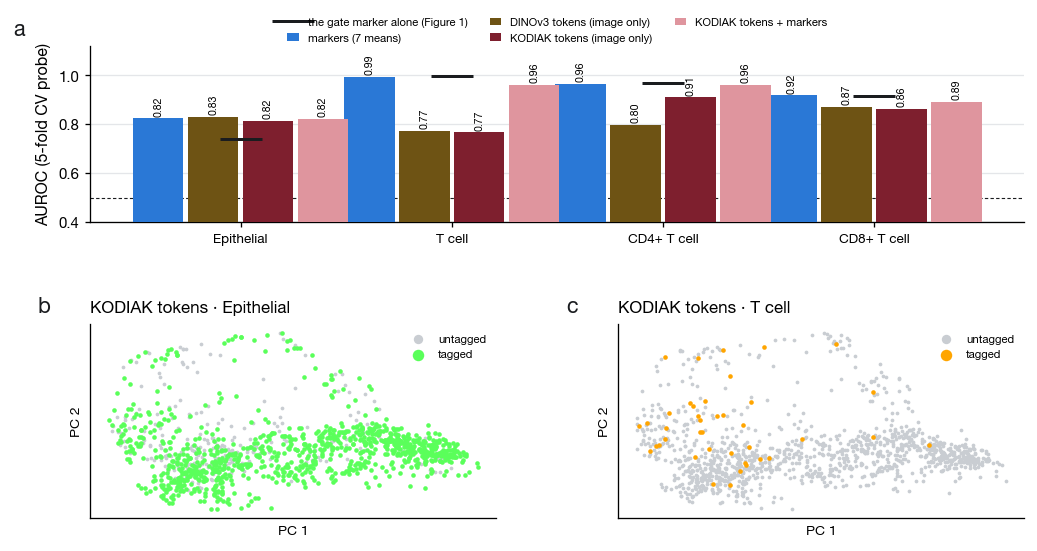

features     DINOv3 tokens (image only)  KODIAK tokens (image only)  KODIAK tokens + markers  markers (7 means)
phenotype                                                                                                      
CD4+ T cell                       0.797                       0.910                    0.960              0.964
CD8+ T cell                       0.870                       0.864                    0.892              0.918
Epithelial                        0.830                       0.815                    0.823              0.825
T cell                            0.773                       0.767                    0.962              0.994


In [5]:
# the two frozen encoders on the segmenter input: LAP2 red, nothing green, DAPI blue — no phenotype marker enters
CH = ("LAP2", None, "DAPI")
NORMS = dataset_norms(DATASET, cfg.slides, ["LAP2", "DAPI"])[SLIDE]
X_in = render_channels(STACK, MARKERS, NORMS, CH)
IN_MEAN = np.array([0.485, 0.456, 0.406], np.float32)[:, None, None]; IN_STD = np.array([0.229, 0.224, 0.225], np.float32)[:, None, None]
X_in = ((X_in - IN_MEAN) / IN_STD).astype(np.float32)
ck = torch.load(PRETRAIN, map_location="cpu", weights_only=False); hp = ck["hyper_parameters"]      # the architecture the run of record trained (ViT-B/16: 768 d, 12 heads)
kodiak = Kodiak(num_prototypes=hp["num_prototypes"], projector_dim=hp["projector_dim"], img_size=hp["img_size"], patch_size=hp["patch_size"],
                embed_dim=hp["embed_dim"], depth=hp["vit_depth"], num_heads=hp["vit_heads"], mlp_ratio=hp["mlp_ratio"], num_storage_tokens=hp["num_storage_tokens"],
                decoder_embed_dim=hp["decoder_embed_dim"], decoder_depth=hp["decoder_depth"], decoder_num_heads=hp["decoder_num_heads"]).eval()
missing, unexpected = kodiak.load_state_dict({k.split("model.", 1)[1]: v for k, v in ck["state_dict"].items() if k.startswith("model.")}, strict=False)
assert not [k for k in missing if k.startswith("teacher_encoder.")], missing
dino = DinoV3Encoder(embed_dim=hp["embed_dim"], depth=hp["vit_depth"], num_heads=hp["vit_heads"], patch_size=hp["patch_size"], img_size=hp["img_size"]).eval()
dstate = torch.load(DINO_W, map_location="cpu", weights_only=False); dino.load_state_dict(dstate.get("model", dstate), strict=True)
ENC = {"KODIAK tokens (image only)": lambda xb: kodiak.teacher_encoder.forward_full(xb)[1], "DINOv3 tokens (image only)": lambda xb: dino.forward_full(xb)[1]}
G = 16

def encode_windows(x, fn, size=256, stride=128, batch=8):
    """Patch tokens of a (3, H, W) input from 256² windows on a 128-px lattice, Hann-blended where windows overlap -> (H/16, W/16, d)."""
    H, W_ = x.shape[1:]
    ys = sorted({*range(0, H - size + 1, stride), H - size}); xs = sorted({*range(0, W_ - size + 1, stride), W_ - size})
    wins = [(y, xx) for y in ys for xx in xs]; g = size // G
    hann = np.hanning(g + 2)[1:-1]; wgt = (np.outer(hann, hann) + 1e-3)[..., None].astype(np.float32)
    acc, cnt = None, np.zeros((H // G, W_ // G, 1), np.float32)
    for i in range(0, len(wins), batch):
        chunk = wins[i:i + batch]
        out = fn(torch.from_numpy(np.stack([x[:, y:y + size, xx:xx + size] for y, xx in chunk]))).numpy()
        if acc is None:
            acc = np.zeros((H // G, W_ // G, out.shape[-1]), np.float32)
        for j, (y, xx) in enumerate(chunk):
            acc[y // G:y // G + g, xx // G:xx // G + g] += out[j].reshape(g, g, -1) * wgt; cnt[y // G:y // G + g, xx // G:xx // G + g] += wgt
    return acc / cnt

t0 = time.perf_counter()
TOK = {name: encode_windows(X_in, fn) for name, fn in ENC.items()}
print(f"tokens: " + ", ".join(f"{k} {v.shape}" for k, v in TOK.items()) + f" ({time.perf_counter() - t0:.0f} s on CPU)")

def cell_features(lab, ids, tokens):
    """A cell's feature = the pixel-weighted mean of the 16-px tokens its mask covers."""
    tok_idx = (np.arange(SIZE)[:, None] // G) * (SIZE // G) + (np.arange(SIZE)[None, :] // G)
    sel = lab > 0
    pairs = pd.DataFrame({"cell": lab[sel], "tok": tok_idx[sel]}).value_counts().reset_index(name="n")
    flat = tokens.reshape(-1, tokens.shape[-1]); F = np.zeros((len(ids), flat.shape[1]), np.float32); pos = {c: i for i, c in enumerate(ids)}
    for cell, grp in pairs.groupby("cell"):
        if cell in pos:
            wts = grp.n.to_numpy(float); F[pos[cell]] = (flat[grp.tok.to_numpy()] * wts[:, None]).sum(0) / wts.sum()
    return F

rows = []
for name, s_ in S.items():
    d, mk = s_["df"], GATE[name]; y = d.positive.to_numpy(); ids = d.cell_id.to_numpy()
    feats = {enc: cell_features(s_["lab"], ids, TOK[enc]) for enc in ENC}
    logm = np.log1p(d[GATE_M].to_numpy())
    scores = {"markers (7 means)": cv_scores(logm, y), "DINOv3 tokens (image only)": cv_scores(feats["DINOv3 tokens (image only)"], y, pca=48),
              "KODIAK tokens (image only)": cv_scores(feats["KODIAK tokens (image only)"], y, pca=48),
              "KODIAK tokens + markers": cv_scores(np.hstack([feats["KODIAK tokens (image only)"], logm]), y, pca=48)}
    s_["feats"] = feats
    for k_, sc in scores.items():
        rows.append({"phenotype": name, "features": k_, "AUROC": auroc(sc, y), "AP": average_precision(sc, y), "prevalence": y.mean()})
rep = pd.DataFrame(rows)
fig = plt.figure(figsize=(7.6, 4.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1], hspace=0.55, wspace=0.3, left=0.08, right=0.99, top=0.86, bottom=0.1)
a = fig.add_subplot(gs[0, :])
for j, k_ in enumerate(ENC_COLOR):
    v = [rep[(rep.phenotype == n) & (rep.features == k_)].AUROC.iloc[0] for n in SESSIONS]
    a.bar(x + (j - 1.5) * w, v, w * 0.92, color=ENC_COLOR[k_], zorder=3, label=k_)
    for xi, vi in zip(x + (j - 1.5) * w, v):
        a.text(xi, vi + 0.01, f"{vi:.2f}", ha="center", fontsize=5.6, rotation=90, va="bottom")
a.plot(x, [S[n]["auroc"] for n in SESSIONS], "_", ms=22, mew=1.6, color=INK, zorder=4, label="the gate marker alone (Figure 1)")
a.axhline(0.5, color=INK, lw=0.6, ls=(0, (3, 2)))
a.set_xticks(x, list(SESSIONS), fontsize=7.2); a.set_ylabel("AUROC (5-fold CV probe)"); a.set_ylim(0.4, 1.12); ygrid(a)
a.legend(fontsize=6.0, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.22), handlelength=1.0)
panel(a, "a", dx=-0.07)
for k, name in enumerate(("Epithelial", "T cell")):
    ax = fig.add_subplot(gs[1, k]); d = S[name]["df"]; y = d.positive.to_numpy()
    Z = PCA(2, random_state=0).fit_transform(StandardScaler().fit_transform(S[name]["feats"]["KODIAK tokens (image only)"]))
    ax.scatter(Z[~y, 0], Z[~y, 1], s=4, color="#C9CDD2", lw=0, label="untagged", rasterized=True)
    ax.scatter(Z[y, 0], Z[y, 1], s=6, color=PANEL.colors[GATE[name]], lw=0, label="tagged", rasterized=True)
    ax.set_xlabel("PC 1", fontsize=7.4); ax.set_ylabel("PC 2", fontsize=7.4); ax.set_title(f"KODIAK tokens · {name}"); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(fontsize=6, markerscale=2.5, loc="best"); panel(ax, "bc"[k], dx=-0.1)
plt.show()
print(rep.pivot(index="phenotype", columns="features", values="AUROC").round(3).to_string())

**Figure 3 — Identity from the image alone.** (a) Probe AUROC per phenotype and feature set. Read it column by column.
*Markers*: the seven intensities together predict the T-cell classes almost perfectly (0.92–0.99), and the epithelium no
better than PanCK alone (0.83 vs 0.74 — the other six markers add a little). *Tokens, image only*: from DAPI and LAP2,
with no phenotype marker visible, both encoders predict the epithelial tag at 0.82–0.83, *better than PanCK itself* — they
read the crypt architecture the biologist typed from — and the T-cell classes at 0.76–0.88, well above chance but below
the markers, because a lymphocyte has a recognizable nucleus and context while CD4 versus CD8 is a marker fact no nuclear
channel shows. *Tokens + markers*: no better than the markers alone — once the intensities are known the image adds
nothing measurable here. KODIAK and DINOv3 are within noise of each other: the slide pretraining does not change what the
representation knows about identity. (b, c) The first two principal components of the KODIAK cell features, tagged cells
in color: the epithelium fills one side of the space, the T cells sit at its stromal edge.

## 5. What each segmenter does to the tagged cells

Now the segmenters. Every fine-tuned model (seed 0) is run on the window on the CPU; HALO's own cells (region 1 is now expert-reviewed: its 320 flagged nuclei are removed, so a tagged cell sitting on one
counts as lost there) and the annotation tool's polygons are added as references. Each tagged cell is carried onto a segmenter's cells by overlap (the predicted
cell with the largest IoU, if at least 0.5), and every mask set is phenotyped with the **same rule**: the calibrated gates
of section 3 for the four tagged markers (set on the tool's polygons; the marker means transfer, Figure 4c), the mixture
gate for the three markers without tags (uPAR, FOXP3, CD45). A tagged cell is then **kept** (a predicted cell covers it and gets the right
identity), **mistyped** (covered, wrong identity) or **lost** (no predicted cell covers it at IoU ≥ 0.5).

segmenters with a finished seed-0 run: U-Net, KODIAK B/16, DINOv3 B/16, KODIAK B/16, frozen, DINOv3 B/16, frozen, Cellpose, adapted


  U-Net                     1068 cells  (6 s)


  KODIAK B/16               1045 cells  (32 s)


  DINOv3 B/16               1023 cells  (58 s)


  KODIAK B/16, frozen        927 cells  (84 s)


  DINOv3 B/16, frozen        963 cells  (109 s)


/Users/marjan/miniforge3/envs/dl/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/Users/marjan/miniforge3/envs/dl/lib/python3.12/site-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/Users/marjan/miniforge3/envs/dl/lib/python3.12/site-packages/segment_anything/modeling/tiny_vit_sam.py:662: UserWarning: Overwriting tiny_vit_5m_224 in registry with segment_anything.modeling.tiny_vit_sam.tiny_vit_5m_224. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  return register_model(fn_wrapper)
/Users/marjan/miniforge3/envs/dl/lib/pyt

  Cellpose, adapted         1111 cells  (358 s)
calibrated gates (raw counts): PanCK 225, CD3 2409, CD4 4713, CD8 1167


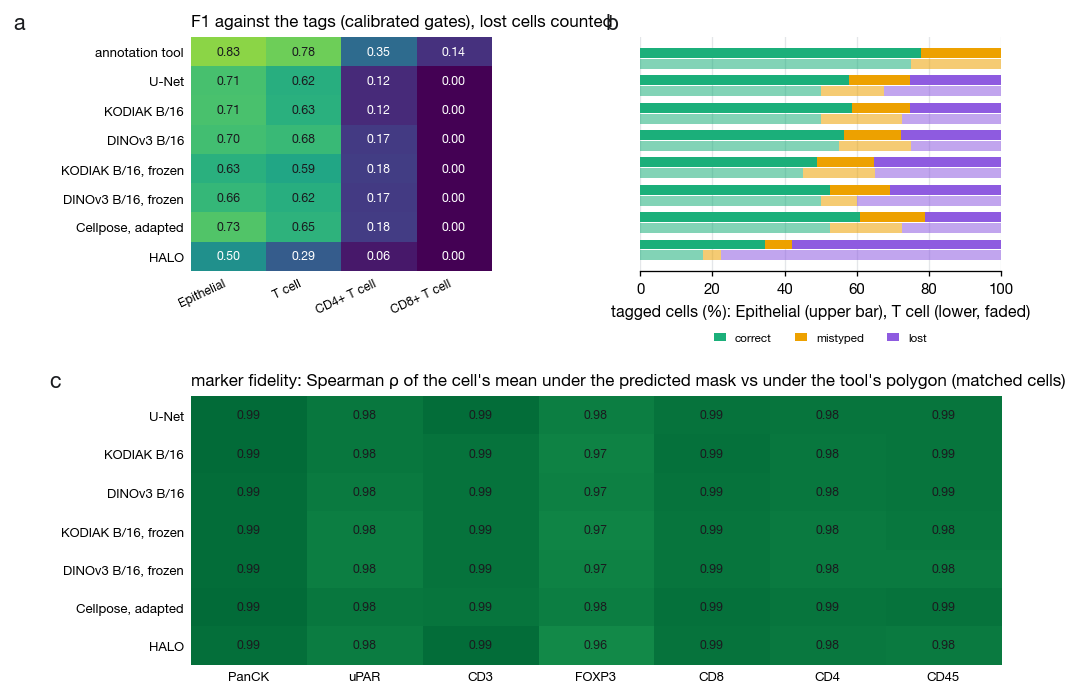

phenotype       CD4+ T cell  CD8+ T cell  Epithelial  T cell
method                                                      
tool                  0.269        0.083       0.778   0.750
unet_flows            0.077        0.000       0.579   0.500
kodiakb_flows         0.077        0.000       0.586   0.500
dinov3b_flows         0.115        0.000       0.565   0.550
kodiakb_frozen        0.115        0.000       0.489   0.450
dinov3b_frozen        0.115        0.000       0.526   0.500
cellpose_ft           0.115        0.000       0.609   0.525
halo                  0.038        0.000       0.346   0.175


In [6]:
avail = [r for r in ROWS if (REPO / "runs" / f"{r}_s{SEED}" / ".finetune_all.done").is_file()]     # finished runs only (weights.pt exists mid-training)
print("segmenters with a finished seed-%d run: " % SEED + ", ".join(LABEL[r] for r in avail))
PRED = {}
t0 = time.perf_counter()
for r in avail:
    kw = {"variant": str(REPO / "runs" / f"{r}_s{SEED}" / "weights.pt"), "gpu": False} if r == "cellpose_ft" else {"weights": str(REPO / "runs" / f"{r}_s{SEED}" / "weights.pt"), "device": "cpu"}
    b, _ = from_config(REPO / "configs" / "baselines" / f"{r}.yaml", **kw)
    b.resolve_input(DATASET, cfg.slides)
    mk_in = b.input_markers()
    image = np.stack([STACK[MARKERS.index(m)] for m in mk_in])
    PRED[r] = predict_tiled(lambda ims, px: b.predict_batch(ims, px, [SLIDE] * len(ims)), image, 256, 192, 8, PX)
    print(f"  {LABEL[r]:<24} {int(PRED[r].max()):>5} cells  ({time.perf_counter() - t0:.0f} s)")
PRED["halo"] = halo_lab

def transfer(lab_from, d, lab_to, min_iou=0.5):
    """Tag every ``lab_to`` cell from the ``lab_from`` cell it overlaps most (IoU >= min_iou): {to_id: positive}; the tool cells left unmatched."""
    g, gids = relabel(lab_from); p, pids = relabel(lab_to)
    if not g.max() or not p.max():
        return {}, set(d.cell_id)
    iou, _, _ = iou_matrix(g, p)
    pos = dict(zip(d.cell_id, d.positive)); out, matched = {}, set()
    for pi in range(iou.shape[1]):
        gi = int(iou[:, pi].argmax())
        if iou[gi, pi] >= min_iou and int(pids[pi + 1]) not in out:
            out[int(pids[pi + 1])] = bool(pos.get(int(gids[gi + 1]), False)); matched.add(int(gids[gi + 1]))
    return out, set(d.cell_id) - matched

CALIBRATED = {GATE[n]: best_threshold(S[n]["df"][GATE[n]], S[n]["df"].positive.to_numpy()) for n in SESSIONS}
print("calibrated gates (raw counts): " + ", ".join(f"{k} {v:.0f}" for k, v in CALIBRATED.items()))
rows, FID, OUTCOME = [], [], {}
for name, s_ in S.items():
    d = s_["df"]; y_all = d.positive.to_numpy()
    for r in ["tool"] + avail + ["halo"]:
        lab = s_["lab"] if r == "tool" else PRED[r]
        ids = np.array(sorted(i for i in np.unique(lab) if i))
        tab = measure(lab, ids)
        thr = {m2: gmm_threshold(tab[m2]) for m2 in GATE_M}                       # markers without tags: the mixture gate
        thr.update(CALIBRATED)                                                    # the tagged markers: the calibrated gates of section 3
        tab["call"] = in_chain(assign(tab, thr), name).to_numpy()
        if r == "tool":
            tags, lost = dict(zip(d.cell_id, d.positive)), set()
        else:
            tags, lost = transfer(s_["lab"], d, lab)
        t = tab[tab.id.isin(list(tags))].copy(); t["positive"] = t.id.map(tags)
        lost_pos = int(d.positive[d.cell_id.isin(list(lost))].sum())
        p = prf(t.call, t.positive)
        n_pos = int(y_all.sum())
        rows.append({"phenotype": name, "method": r, "correct": p["tp"], "mistyped": p["fn"], "lost": lost_pos, "n_tagged": n_pos, "precision": p["precision"],
                     "recall_matched": p["recall"], "recall_total": p["tp"] / max(n_pos, 1), "F1": 2 * p["tp"] / max(2 * p["tp"] + p["fp"] + p["fn"] + lost_pos, 1)})
        OUTCOME[(name, r)] = dict(lab=lab, tab=t, lost=lost)
        if r not in ("tool",):                                                     # marker fidelity: predicted mask vs the tool's polygon, matched cells
            m2 = t.merge(d.merge(measure(s_["lab"], d.cell_id.to_numpy()), left_on="cell_id", right_on="id")[["cell_id"] + GATE_M].rename(columns={m_: f"{m_}_tool" for m_ in GATE_M}),
                         left_on=t.id.map({v: k for k, v in {}.items()}).fillna(-1), right_on="cell_id", how="inner") if False else None
    # marker fidelity via the transfer map: recompute pairs id -> tool id
    for r in avail + ["halo"]:
        g, gids = relabel(s_["lab"]); p_, pids = relabel(PRED[r]); iou, _, _ = iou_matrix(g, p_)
        pairs = [(int(gids[int(iou[:, pi].argmax()) + 1]), int(pids[pi + 1])) for pi in range(iou.shape[1]) if iou[:, pi].max() >= 0.5]
        if not pairs or name != "Epithelial":
            continue                                                                # one session's polygons suffice for fidelity (all cells)
        tool_tab = measure(s_["lab"], [a_ for a_, _ in pairs]); pred_tab = measure(PRED[r], [b_ for _, b_ in pairs])
        for m2 in GATE_M:
            FID.append({"method": r, "marker": m2, "rho": spearmanr(tool_tab[m2], pred_tab[m2]).correlation, "n": len(pairs)})
res = pd.DataFrame(rows); fid = pd.DataFrame(FID)
ORDER = ["tool"] + avail + ["halo"]
fig = plt.figure(figsize=(7.6, 5.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], width_ratios=[1, 1.2], hspace=0.5, wspace=0.45, left=0.2, right=0.99, top=0.95, bottom=0.12)
a = fig.add_subplot(gs[0, 0])
Mx = res.pivot(index="method", columns="phenotype", values="F1").reindex(index=ORDER, columns=list(SESSIONS))
a.imshow(Mx.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
for i in range(Mx.shape[0]):
    for j in range(Mx.shape[1]):
        a.text(j, i, f"{Mx.values[i, j]:.2f}", ha="center", va="center", fontsize=6.6, color="white" if Mx.values[i, j] < 0.55 else INK)
a.set_xticks(range(len(SESSIONS)), list(SESSIONS), fontsize=6.6, rotation=25, ha="right"); a.set_yticks(range(len(ORDER)), [LABEL[r] for r in ORDER], fontsize=7)
a.set_title("F1 against the tags (calibrated gates), lost cells counted"); a.tick_params(length=0)
for sp in a.spines.values(): sp.set_visible(False)
panel(a, "a", dx=-0.55, dy=1.02)
b_ = fig.add_subplot(gs[0, 1])
yy = np.arange(len(ORDER))[::-1]
for k, name in enumerate(("Epithelial", "T cell")):
    sub = res[res.phenotype == name].set_index("method").reindex(ORDER)
    off = 0.2 if k == 0 else -0.2; left = np.zeros(len(ORDER))
    for cls in OUT_COLOR:
        v = 100 * sub[cls].values / sub.n_tagged.values
        b_.barh(yy + off, v, left=left, height=0.36, color=OUT_COLOR[cls], zorder=3, alpha=1.0 if k == 0 else 0.55, label=cls if k == 0 else None); left += v
b_.set_yticks(yy, [""] * len(ORDER)); b_.set_xlim(0, 100); b_.set_xlabel("tagged cells (%): Epithelial (upper bar), T cell (lower, faded)")
b_.legend(fontsize=6.2, loc="upper center", bbox_to_anchor=(0.5, -0.22), handlelength=1.0, ncol=3); xgrid(b_); b_.spines["left"].set_visible(False); b_.tick_params(axis="y", length=0)
panel(b_, "b", dx=-0.06, dy=1.02)
c = fig.add_subplot(gs[1, :])
if len(fid):
    F = fid.pivot(index="method", columns="marker", values="rho").reindex(index=[r for r in ORDER if r != "tool"], columns=GATE_M)
    c.imshow(F.values, cmap="RdYlGn", vmin=0.5, vmax=1, aspect="auto")
    for i in range(F.shape[0]):
        for j in range(F.shape[1]):
            c.text(j, i, f"{F.values[i, j]:.2f}", ha="center", va="center", fontsize=6.6, color=INK)
    c.set_xticks(range(len(GATE_M)), GATE_M, fontsize=7); c.set_yticks(range(F.shape[0]), [LABEL[r] for r in F.index], fontsize=7)
    c.set_title("marker fidelity: Spearman ρ of the cell's mean under the predicted mask vs under the tool's polygon (matched cells)"); c.tick_params(length=0)
    for sp in c.spines.values(): sp.set_visible(False)
panel(c, "c", dx=-0.16, dy=1.02)
plt.show()
print("F1 against the tags, lost cells counted:"); print(res.pivot(index="method", columns="phenotype", values="F1").reindex(index=ORDER).round(3).to_string())
print("\nrecall over all tagged cells:"); print(res.pivot(index="method", columns="phenotype", values="recall_total").reindex(index=ORDER).round(3).to_string())
print("\nfate of the tagged cells (correct / mistyped / lost of n_tagged):")
print(res.set_index(["phenotype", "method"])[["correct", "mistyped", "lost", "n_tagged"]].unstack("phenotype").reindex(ORDER).to_string())
if len(fid):
    print("\nmarker fidelity (Spearman rho, predicted mask vs tool polygon):"); print(fid.pivot(index="method", columns="marker", values="rho").reindex(index=[r for r in ORDER if r != "tool"], columns=GATE_M).round(3).to_string())

**Figure 4 — The segmenter's share of the phenotype error.** (a) F1 of the phenotype call against the tags per
segmenter and phenotype, a tagged cell that no predicted cell covers counting as an error. The annotation tool's own
polygons are the ceiling (no cell can be lost there), HALO is the reference the paper scores segmentation against. (b) For
the two phenotypes with enough tags, the fate of every tagged cell: kept, mistyped, lost. Since the gate is identical
across rows, the difference between rows is the segmenter's doing, and it is almost all in the *lost* share. (c) How
faithfully each mask reproduces the marker means the tool's polygon gives the same cells (Spearman correlation, matched
cells): 0.97–0.99 for every segmenter, every marker, HALO included. A segmenter does not distort the intensities of the
cells it finds; its phenotype error is the cells it does not find.

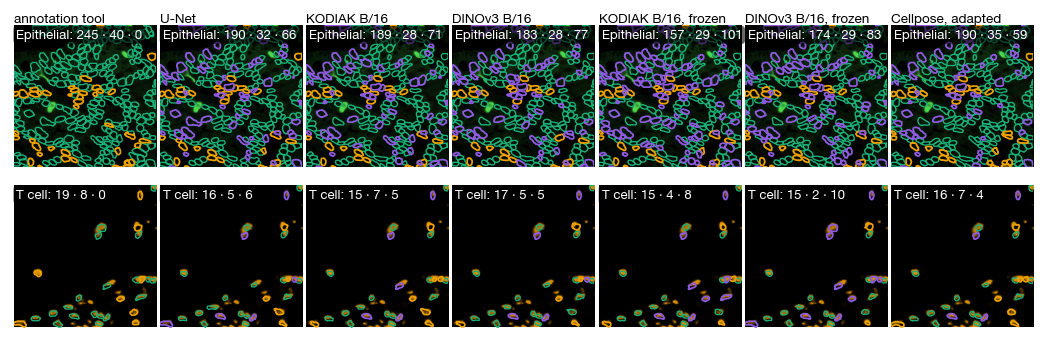

chips: kept with the right identity (green) · found but mistyped (amber) · lost by the segmentation (violet), tagged cells of the crop; the tool column has no losses by construction


In [7]:
show = ["tool"] + avail
fig, axes = plt.subplots(2, len(show), figsize=(7.6, 7.6 / len(show) * 2 + 0.4), squeeze=False)
fig.subplots_adjust(wspace=0.03, hspace=0.05, left=0.003, right=0.997, top=0.95, bottom=0.05)

def outlines(ax, lab, ids, color, lw=0.6):
    segs = []
    for cid in ids:
        cs, _ = cv2.findContours((lab == cid).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        segs += [c[:, 0, :] for c in cs if len(c) > 2]
    if segs:
        ax.add_collection(LineCollection([np.vstack([s_, s_[:1]]) for s_ in segs], colors=color, linewidths=lw))

for i, name in enumerate(("Epithelial", "T cell")):
    d, mk = S[name]["df"], GATE[name]
    y0, x0 = CROPS[name]; sl = (slice(y0, y0 + 512), slice(x0, x0 + 512))
    base = np.clip(scaled(IMG[mk][sl], stats.lo[mk], stats.hi[mk]) * 1.6, 0, 1) ** 0.8
    base = np.clip(base[..., None] * hexrgb(PANEL.colors[mk])[None, None] * 0.85, 0, 1)
    for j, r in enumerate(show):
        ax = axes[i, j]; o = OUTCOME[(name, r)]; lab = o["lab"][sl]; t = o["tab"]
        ax.imshow(base)
        here = set(np.unique(lab)) - {0}; here_tool = set(np.unique(S[name]["lab"][sl])) - {0}
        pos = t[t.positive & t.id.isin(here)]
        lost_here = [c_ for c_ in o["lost"] if c_ in here_tool and d.positive[d.cell_id == c_].any()]
        outlines(ax, lab, pos[pos.call].id, OUT_COLOR["correct"], 0.7)
        outlines(ax, lab, pos[~pos.call].id, OUT_COLOR["mistyped"], 0.9)
        outlines(ax, S[name]["lab"][sl], lost_here, OUT_COLOR["lost"], 0.9)
        ax.set_axis_off()
        if i == 0:
            ax.set_title(LABEL[r], fontsize=7.2, pad=2)
        chip(ax, f"{name}: {int(pos.call.sum())} · {int((~pos.call).sum())} · {len(lost_here)}")
plt.show()
print("chips: kept with the right identity (green) · found but mistyped (amber) · lost by the segmentation (violet), tagged cells of the crop; the tool column has no losses by construction")

**Figure 5 — The same tagged cells through every segmenter.** Two 512² crops of the window on the gate marker — the
crypt field for Epithelial (top), the stromal corner where the T cells are for T cell (bottom) — each tagged cell of the
crop outlined by its fate under each segmenter: right identity kept, found but mistyped, or lost, counts in the chips.
Epithelial losses cluster where crypt cells touch and become one object; mistypes sit on the dim end of PanCK and are the
gate's. The violet T cells are a matching artifact to keep in mind: every segmenter draws a nucleus there, but the
tool's T-cell polygons are whole cells with their CD3-bright membrane, so the nuclear mask overlaps them below the IoU 0.5
used to carry a tag across, and the cell counts as lost. Under a centroid-based transfer those cells would be found, and
their CD3 mean inside the nucleus is what then decides the identity.

## 6. The test slide: how much the phenotype composition depends on the gate

The test slide's expert cells carry no tags in this notebook (its own tagged windows, `SLIDE-0236/phenotyping/`, are the
subject of notebook 00d and are not used here), so no gate is *checked* on them; the question is how much the composition
rests on the choice of gate. The paper's rule in `configs/panel.yaml` is set by `scripts/calibrate_gates.py` on the unified
store of the development slide (the R11/R12 boxes and the W1 tags): PanCK, CD3, CD4, CD8 and FOXP3 are calibrated there in
normalized units, uPAR and CD45 have no tags and carry a *provisional* label-free mixture gate, identical for every method
and flagged as unvalidated. Below, the expert cells of the test slide phenotyped under that rule and under a fully automatic
rule (mixture gates for every marker), to show what the calibrated gates change and how much of the composition still rests
on the provisional ones. The cell needs `outputs/analysis/cells_expert.csv` from notebook 03 and says so when it is missing.


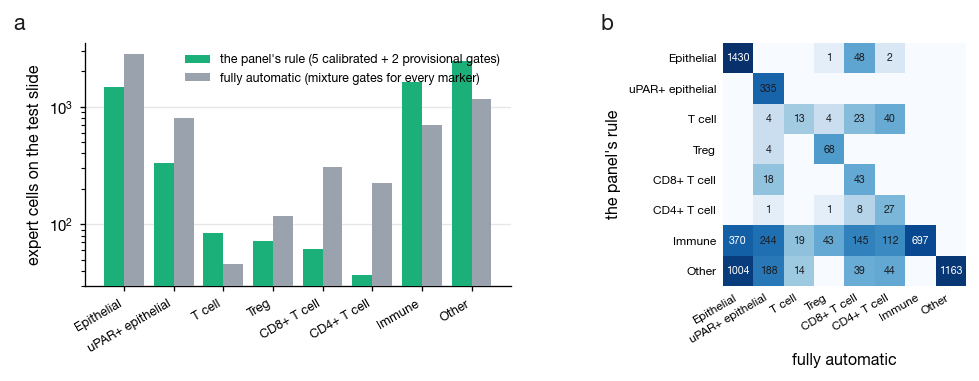

6,152 expert cells of the test slide: 38.6 % change phenotype between the panel's rule and the fully automatic one | Epithelial: 1481 -> 2804, uPAR+ epithelial: 335 -> 794, T cell: 84 -> 46, Treg: 72 -> 117, CD8+ T cell: 61 -> 306, CD4+ T cell: 37 -> 225, Immune: 1630 -> 697, Other: 2452 -> 1163


In [8]:
EXP_CSV = next((ANALYSIS / f for f in ("cells_expert_SLIDE-0236.csv", "cells_expert.csv") if (ANALYSIS / f).is_file()), None)   # written by notebook 03
exp = pd.read_csv(EXP_CSV) if EXP_CSV else None
if exp is None:
    print("run notebook 03 first — outputs/analysis/cells_expert_SLIDE-0236.csv gives the test slide's expert cells with their seven marker means")
else:
    print(f"expert cells from {EXP_CSV.name}")
    stats_t = NormStats.load(DATASET / "SLIDE-0236" / "stats.json")
    PANEL_GATES = load_panel(REPO / "configs" / "panel.yaml").gates                                          # the paper's rule, as written in configs/panel.yaml
    thr_o = {m2: stats_t.lo[m2] + float(PANEL_GATES[m2]) * (stats_t.hi[m2] - stats_t.lo[m2]) for m2 in GATE_M}
    thr_g = {m2: gmm_threshold(exp[m2]) for m2 in GATE_M}                                                     # automatic, fitted here
    po, pg = assign(exp, thr_o), assign(exp, thr_g)
    names = PANEL.names + ["Other"]
    co, cg = po.value_counts().reindex(names).fillna(0), pg.value_counts().reindex(names).fillna(0)
    fig = plt.figure(figsize=(7.6, 3.0))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.3, 1], wspace=0.45, left=0.08, right=0.98, top=0.88, bottom=0.28)
    a = fig.add_subplot(gs[0]); xx = np.arange(len(names))
    a.bar(xx - 0.2, co.values, 0.4, color=GATE_COLOR["calibrated gate (from the tags, CV)"], zorder=3, label="the panel's rule (5 calibrated + 2 provisional gates)"); a.bar(xx + 0.2, cg.values, 0.4, color=GATE_COLOR["mixture gate (automatic)"], zorder=3, label="fully automatic (mixture gates for every marker)")
    a.set_xticks(xx, names, rotation=30, ha="right", fontsize=6.8); a.set_ylabel("expert cells on the test slide"); a.set_yscale("log"); ygrid(a); a.legend(fontsize=6.6)
    panel(a, "a", dx=-0.14)
    b_ = fig.add_subplot(gs[1])
    conf = pd.crosstab(po, pg).reindex(index=names, columns=names).fillna(0)
    b_.imshow(np.log1p(conf.values), cmap="Blues")
    for i in range(len(names)):
        for j in range(len(names)):
            if conf.values[i, j]:
                b_.text(j, i, f"{int(conf.values[i, j])}", ha="center", va="center", fontsize=5.6, color="white" if conf.values[i, j] > conf.values.max() / 4 else INK)
    b_.set_xticks(range(len(names)), names, rotation=30, ha="right", fontsize=6.4); b_.set_yticks(range(len(names)), names, fontsize=6.4)
    b_.set_xlabel("fully automatic"); b_.set_ylabel("the panel's rule"); b_.tick_params(length=0)
    for sp in b_.spines.values(): sp.set_visible(False)
    panel(b_, "b", dx=-0.45)
    plt.show()
    print(f"{len(exp):,} expert cells of the test slide: {100 * (po != pg).mean():.1f} % change phenotype between the panel's rule and the fully automatic one | "
          + ", ".join(f"{n}: {int(co[n])} -> {int(cg[n])}" for n in names))

**Figure 6 — What the calibration changes on the test slide, and what it cannot.** The expert cells of the test slide phenotyped
under the panel's rule and under a fully automatic one: (a) the resulting composition, (b) where cells move. The cells that move
are the classes whose gates are calibrated (the T-cell classes and the epithelium) and the splits that rest on the provisional
uPAR and CD45 gates. The lesson of this notebook is the size of that dependence: the identity of a cell depends on the gating rule
far more than on the segmenter that found it (a few percent between segmenters in notebook 03), so the rule has to be fixed against
a human reference before segmentation differences downstream can mean anything. The tags for uPAR and CD45 are still missing;
Slide 2's own tagged windows (notebook 00d) are the next reference to check the carried-over gates against.
